<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FOil-Spill-Detection/notebooks/oil-spill/C4_04_train_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C4 – Step 5: Train and compare 3 models
**What it does:** trains **Logistic Regression, Random Forest and XGBoost** on `features.csv`, evaluates them on the **test data**, and selects the best model.

⏳ The whole notebook takes **3–5 minutes**. Use **Runtime → Run all** and wait. (Images are not processed again; only the table is used.)

## 1. Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Load the features table

In [ ]:
import os, sys, time, json, numpy as np, pandas as pd
DRIVE_DIR = '/content/drive/MyDrive/C4_OilSpill'
DATA_DIR  = f'{DRIVE_DIR}/data'
RES_DIR   = f'{DRIVE_DIR}/results'
MODEL_DIR = f'{DRIVE_DIR}/models'
os.makedirs(RES_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)

sys.path.insert(0, DRIVE_DIR)
from c4_features import FEATURES

data = pd.read_csv(f'{DATA_DIR}/features.csv')
train, test = data[data.split == 'train'], data[data.split == 'test']
X_train, y_train = train[FEATURES], train['y']
X_test,  y_test  = test[FEATURES],  test['y']

print(f'Features : {len(FEATURES)}')
print(f'Train    : {len(train):,} patches  (oil {y_train.sum():,} | look-alike {(y_train==0).sum():,})')
print(f'Test     : {len(test):,} patches  (oil {y_test.sum():,} | look-alike {(y_test==0).sum():,})')

Features : 19
Train    : 26,301 patches  (oil 4,138 | look-alike 22,163)
Test     : 5,683 patches  (oil 621 | look-alike 5,062)


## 3. Helper: train → predict → evaluate
For each model:
1. **Train** (learn from the training data)
2. **Predict** (on test data the model has never seen)
3. **Evaluate**:

| Metric | Meaning |
|---|---|
| **Precision** | Of the patches the model called *oil*, how many are really oil |
| **Recall** | Of the real oil patches, how many the model found |
| **F1** | Combines precision and recall ⭐ (**main metric**) |
| **ROC-AUC** | Ability to separate oil from look-alikes (1.0 = perfect) |
| Accuracy | Overall % correct (misleading on imbalanced data, so not used *alone*) |

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

results, models = [], {}

def evaluate(name, model):
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    r = dict(Model=name,
             Precision=precision_score(y_test, pred, zero_division=0),
             Recall=recall_score(y_test, pred),
             F1=f1_score(y_test, pred),
             ROC_AUC=roc_auc_score(y_test, prob),
             Accuracy=accuracy_score(y_test, pred),
             Train_sec=train_time)
    results.append(r); models[name] = model
    print(f"{name}\n  Precision {r['Precision']:.3f} | Recall {r['Recall']:.3f} | F1 {r['F1']:.3f} | "
          f"ROC-AUC {r['ROC_AUC']:.3f} | Accuracy {r['Accuracy']:.3f} | Train {train_time:.1f}s")
    return model

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
print(f'Oil : Look-alike = 1 : {neg/pos:.1f}  -> using class weights')

Oil : Look-alike = 1 : 5.4  -> using class weights


## 4. 🔵 Model 1: Logistic Regression (baseline)
Features are scaled (PowerTransformer), `class_weight='balanced'`.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LogisticRegression

lr = make_pipeline(PowerTransformer(),
                   LogisticRegression(class_weight='balanced', max_iter=3000, random_state=42))
evaluate('Logistic Regression', lr);

Logistic Regression
  Precision 0.374 | Recall 0.786 | F1 0.507 | ROC-AUC 0.900 | Accuracy 0.833 | Train 0.9s


## 5. 🌲 Model 2: Random Forest
300 decision trees, `class_weight='balanced_subsample'`.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced_subsample',
                            n_jobs=-1, random_state=42)
evaluate('Random Forest', rf);

Random Forest
  Precision 0.790 | Recall 0.671 | F1 0.726 | ROC-AUC 0.949 | Accuracy 0.945 | Train 24.6s


## 6. ⚡ Model 3: XGBoost
400 boosted trees (each one corrects the previous ones), `scale_pos_weight` = imbalance ratio.

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=neg/pos, eval_metric='logloss',
                    n_jobs=-1, random_state=42)
evaluate('XGBoost', xgb);

XGBoost
  Precision 0.632 | Recall 0.823 | F1 0.715 | ROC-AUC 0.958 | Accuracy 0.928 | Train 1.5s


## 7. 📊 Compare the 3 models
**The model with the highest F1 is the best model.**

In [ ]:
res = pd.DataFrame(results).set_index('Model').round(3)
res.to_csv(f'{RES_DIR}/04_model_comparison.csv')
best_name = res['F1'].idxmax()
print(f'🏆 Best model: {best_name} (F1 = {res.loc[best_name, "F1"]:.3f})')
res

🏆 Best model: Random Forest (F1 = 0.726)


,Precision,Recall,F1,ROC_AUC,Accuracy,Train_sec
Model,,,,,,
Logistic Regression,0.374,0.786,0.507,0.900,0.833,0.912
Random Forest,0.790,0.671,0.726,0.949,0.945,24.602
XGBoost,0.632,0.823,0.715,0.958,0.928,1.514


## 8. Confusion matrices (all 3 models)
Diagonal (top-left → bottom-right) = **correct** predictions. Other cells = errors.

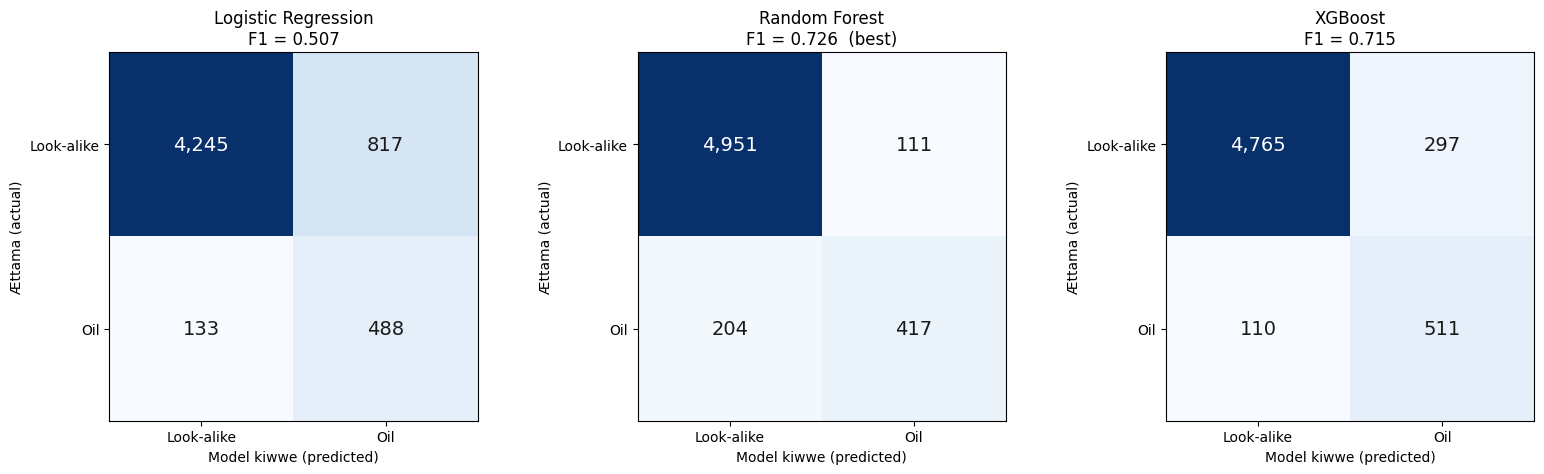

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, m) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, (m.predict_proba(X_test)[:, 1] >= 0.5).astype(int))
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=14,
                    color='white' if cm[i, j] > cm.max() / 2 else '#1a1a19')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Look-alike', 'Oil'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Look-alike', 'Oil'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f"{name}\nF1 = {res.loc[name, 'F1']:.3f}" + ('  (best)' if name == best_name else ''))
plt.tight_layout()
plt.savefig(f'{RES_DIR}/04_confusion_matrices.png', dpi=120)
plt.show()

## 9. Feature importance: which features does the model rely on most?
Importance for both Random Forest and XGBoost.

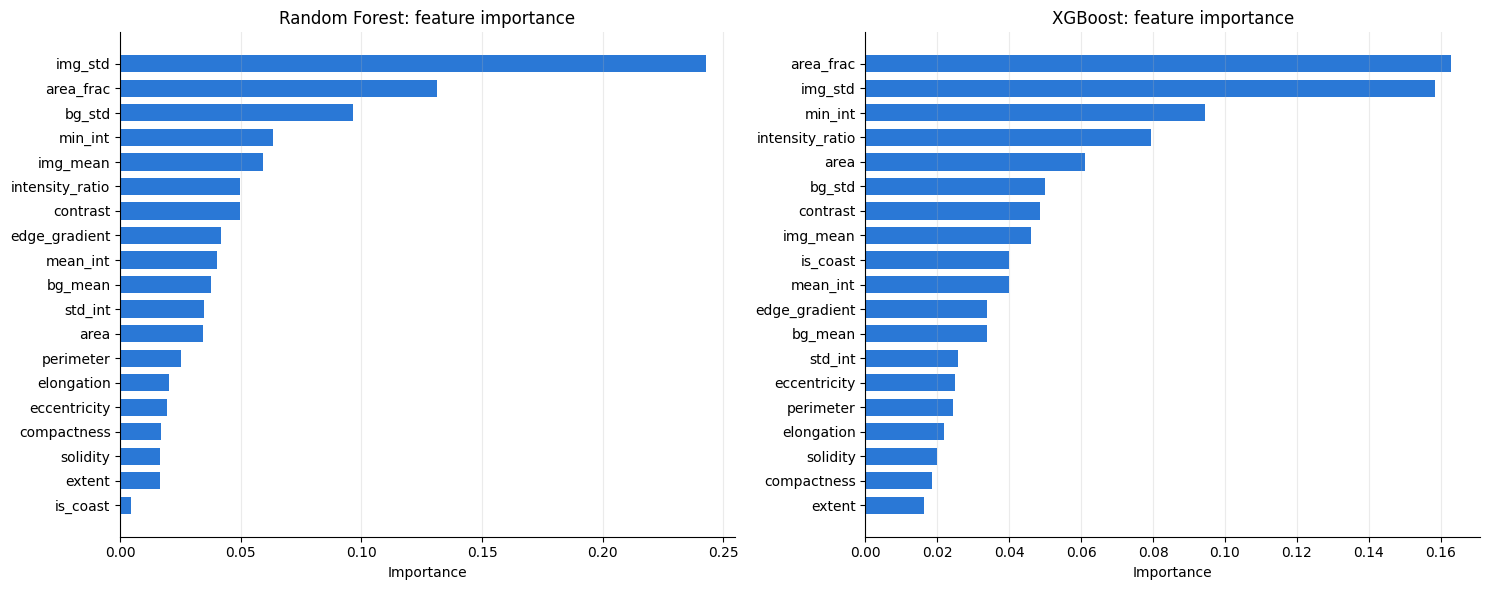

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name in zip(axes, ['Random Forest', 'XGBoost']):
    imp = pd.Series(models[name].feature_importances_, index=FEATURES).sort_values()
    ax.barh(imp.index, imp.values, color='#2a78d6', height=0.7)
    ax.set_title(f'{name}: feature importance'); ax.set_xlabel('Importance')
    ax.grid(axis='x', alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{RES_DIR}/04_feature_importance.png', dpi=120)
plt.show()

## 10. Save the 3 models to Drive (for the frontend)

In [ ]:
import joblib
files = {'Logistic Regression': 'logistic_regression.pkl', 'Random Forest': 'random_forest.pkl', 'XGBoost': 'xgboost.pkl'}
for name, fn in files.items():
    joblib.dump(models[name], f'{MODEL_DIR}/{fn}')

meta = dict(features=FEATURES, best_model=best_name, files=files, threshold=0.5,
            metrics=res.reset_index().to_dict(orient='records'))
with open(f'{MODEL_DIR}/model_info.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('Saved ✅', os.listdir(MODEL_DIR))

Saved ✅ ['logistic_regression.pkl', 'random_forest.pkl', 'xgboost.pkl', 'model_info.json']


## ⭐ Bonus: 5-fold cross-validation
The test set is used only once. To check that the models are **stable**, the training data is split into 5 parts and the models are trained/validated 5 times (all patches from one satellite pass stay in the same part). Takes about 2–4 minutes.

In [ ]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.base import clone

gkf = GroupKFold(n_splits=5)
cv_rows = []
for name, m in models.items():
    s = cross_val_score(clone(m), X_train, y_train, groups=train['start_time'], cv=gkf, scoring='f1', n_jobs=1)
    cv_rows.append(dict(Model=name, CV_F1_mean=s.mean(), CV_F1_std=s.std()))
    print(f'{name:20s} CV F1 = {s.mean():.3f} ± {s.std():.3f}')
pd.DataFrame(cv_rows).round(3).to_csv(f'{RES_DIR}/04_cross_validation.csv', index=False)

Logistic Regression  CV F1 = 0.570 ± 0.034
Random Forest        CV F1 = 0.763 ± 0.045
XGBoost              CV F1 = 0.759 ± 0.044


## ✅ Done!
Saved to Drive:
- `results/04_model_comparison.csv` → **results table** (PP1)
- `results/04_confusion_matrices.png` → **confusion matrices** (PP1)
- `results/04_feature_importance.png` → **feature importance** (PP1)
- `models/*.pkl` + `model_info.json` → for the **frontend**

**🔔 COMMIT:** File → Save a copy in GitHub → `notebooks/oil-spill/C4_04_train_models.ipynb` → `feat(oil-spill): train and evaluate LR, RF and XGBoost classifiers`